# CIFAR-10: CNN versus FCNN

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Compare dense and convolutional models on ten image classes.

**Approach:** TensorFlow/Keras architecture comparison.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Part 1 Project 3 (CIFAR-10 Deep Classification) CNN </span>
    </span>
    </center>
<br>


## (CIFAR-10 Deep Classification)
### GUERBOUZ MOHAMMED ALAA EDDINE

In [3]:
# Import necessary libraries
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

#### **Explanation:**
- We import TensorFlow and Keras for building and training the deep learning models.
- Matplotlib is used for visualizing the images.
- NumPy is used for numerical operations on the dataset. np

In [4]:
# Load the CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Define class names for CIFAR-10
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

#### **Explanation:**
- The CIFAR-10 dataset is loaded using TensorFlow's `keras.datasets.cifar10`.
- The dataset is split into training and testing sets:
  - `X_train` and `y_train` are used for training the model.
  - `X_test` and `y_test` are used for evaluating the model.
- `class_names` is a list of the 10 categories in the dataset.

Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Test images shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)


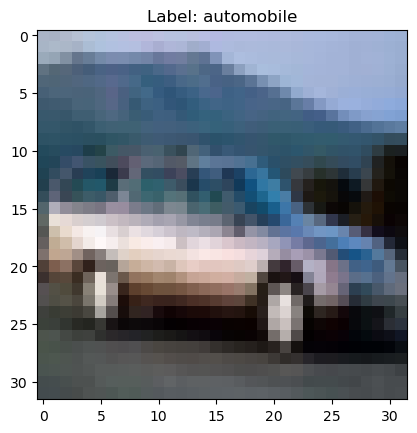

In [9]:
# Check the shape of the dataset
print("Training images shape:", X_train.shape)  # (50000, 32, 32, 3)
print("Training labels shape:", y_train.shape)  # (50000, 1)
print("Test images shape:", X_test.shape)       # (10000, 32, 32, 3)
print("Test labels shape:", y_test.shape)       # (10000, 1)

# Display the first image in the training set
plt.figure()
plt.imshow(X_train[4])
plt.title(f"Label: {class_names[y_train[4][0]]}")
plt.show()

#### **Explanation:**
- We check the shape of the dataset to confirm that there are 50,000 training images and 10,000 test images, each of size 32x32 pixels with 3 color channels (RGB).
- We visualize the first image in the training set using `matplotlib`. The title of the plot shows the corresponding label (e.g., "airplane").

In [10]:
# Normalize the pixel values to the range [0, 1]
X_train = X_train / 255.0
X_test = X_test / 255.0

# Convert labels to one-hot encoding (optional for FCNN)
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)


#### **Explanation:**
- The pixel values are normalized to the range `[0, 1]` by dividing by 255. This helps the model converge faster during training.
- The labels are converted to one-hot encoded vectors, which are required for certain loss functions like `categorical_crossentropy`. If you use `sparse_categorical_crossentropy`, this step is optional.l.

In [11]:
# Define the CNN model
cnn_model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),  # First convolutional layer
    layers.MaxPooling2D((2, 2)),                                           # First max-pooling layer
    layers.Conv2D(64, (3, 3), activation='relu'),                          # Second convolutional layer
    layers.MaxPooling2D((2, 2)),                                           # Second max-pooling layer
    layers.Conv2D(128, (3, 3), activation='relu'),                         # Third convolutional layer
    layers.Flatten(),                                                      # Flatten the output for dense layers
    layers.Dense(128, activation='relu'),                                  # Fully connected layer
    layers.Dense(10, activation='softmax')                                 # Output layer with softmax activation
])

# Compile the CNN model
cnn_model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

# Print the model summary
cnn_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 30, 30, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 15, 15, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 13, 13, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 6, 6, 64)          0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 4, 4, 128)         73856     
                                                                 
 flatten (Flatten)           (None, 2048)              0

#### **Explanation:**
- We build a **Convolutional Neural Network (CNN)** using Keras' `Sequential` API.
- The model consists of:
  - Three **convolutional layers** with ReLU activation to extract features from the images.
  - Two **max-pooling layers** to reduce the spatial dimensions.
  - A **flatten layer** to convert the 2D feature maps into a 1D vector.
  - A **fully connected (dense) layer** with 128 neurons and ReLU activation.
  - An **output layer** with 10 neurons (one for each class) and softmax activation to output class probabilities.
- The model is compiled using the Adam optimizer, categorical cross-entropy loss, and accuracy as the evaluation metric.

In [14]:
cnn_history = cnn_model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test))


Epoch 1/10
1563/1563 [==============================] - 24s 15ms/step - loss: 1.4473 - accuracy: 0.4738 - val_loss: 1.1743 - val_accuracy: 0.5819
Epoch 2/10
1563/1563 [==============================] - 22s 14ms/step - loss: 1.0711 - accuracy: 0.6215 - val_loss: 1.0098 - val_accuracy: 0.6460
Epoch 3/10
1563/1563 [==============================] - 22s 14ms/step - loss: 0.9120 - accuracy: 0.6783 - val_loss: 0.9796 - val_accuracy: 0.6599
Epoch 4/10
1563/1563 [==============================] - 23s 15ms/step - loss: 0.7957 - accuracy: 0.7210 - val_loss: 0.8524 - val_accuracy: 0.7081
Epoch 5/10
1563/1563 [==============================] - 23s 14ms/step - loss: 0.7128 - accuracy: 0.7512 - val_loss: 0.8766 - val_accuracy: 0.7037
Epoch 6/10
1563/1563 [==============================] - 23s 14ms/step - loss: 0.6316 - accuracy: 0.7776 - val_loss: 0.8554 - val_accuracy: 0.7136
Epoch 7/10
1563/1563 [==============================] - 23s 15ms/step - loss: 0.5597 - accuracy: 0.8028 - val_loss: 0.8975 -

#### **Explanation:**
- Both models are trained for 10 epochs using the training data.
- The `validation_data` parameter allows the models to evaluate their performance on the test set after each epoch.

In [19]:
# Evaluate the CNN model
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(X_test, y_test)
print(f"CNN Test Accuracy: {cnn_test_acc:.4f}")

test_loss, test_acc = cnn_model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")
print('\nLoss on the TEST Set: {:,.3f}'.format(test_loss))
print('Accuracy on the TEST Set: {:.3%}'.format(test_acc))

313/313 [==============================] - 1s 4ms/step - loss: 0.9602 - accuracy: 0.7202
CNN Test Accuracy: 0.7202
313/313 [==============================] - 1s 4ms/step - loss: 0.9602 - accuracy: 0.7202
Test Accuracy: 0.7202

Loss on the TEST Set: 0.960
Accuracy on the TEST Set: 72.020%


#### **Explanation:**
- The models' performance is evaluated on the test set using the `evaluate()` function.
- The test accuracy is printed, which indicates how well the models generalize to unseen data.a.

In [25]:
# Make predictions using the CNN model
cnn_predictions = cnn_model.predict(X_test)

# Display the predicted class for the first test image
cnn_predicted_class = np.argmax(cnn_predictions[0])
print(f"CNN Predicted Class: {class_names[cnn_predicted_class]}")
print(f"Actual Class: {class_names[np.argmax(y_test[0])]}")

313/313 [==============================] - 1s 4ms/step
CNN Predicted Class: cat
Actual Class: cat


#### **Explanation:**
- The models make predictions on the test set using the `predict()` function.
- The predicted class for the first test image is displayed, along with the actual class.

### Loss and Validation Plots

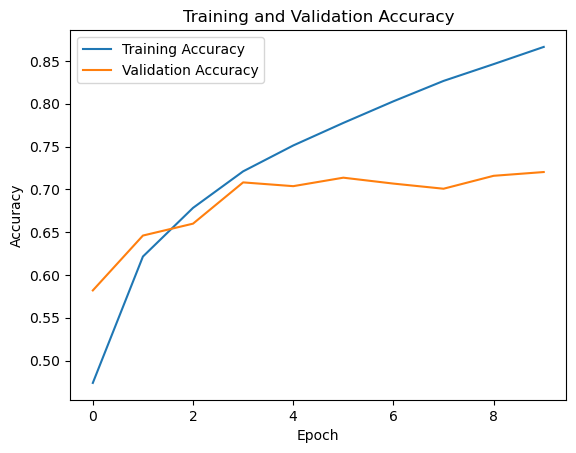

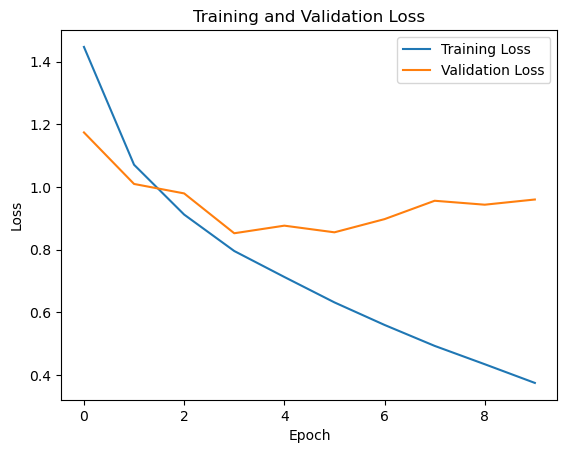

In [27]:
# Plot training and validation accuracy
plt.plot(cnn_history.history['accuracy'], label='Training Accuracy')
plt.plot(cnn_history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss
plt.plot(cnn_history.history['loss'], label='Training Loss')
plt.plot(cnn_history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

#### **Explanation:**
- The training and validation accuracy are plotted over the epochs to visualize the model's learning progress.
- The training and validation loss are also plotted to check for overfitting or underfitting.

### Test our model with an image from dataset 

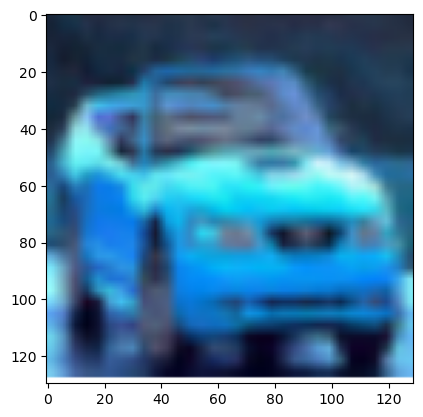

In [31]:
import cv2  
img = cv2.imread('testimg.png')
plt.imshow(img)


In [33]:
from keras.preprocessing.image import img_to_array, load_img
img = cv2.resize(img, (32, 32))  # Assuming the model expects input images of size 32x32

# Convert the image to array and normalize pixel values
img_array = img_to_array(img)
img_array = img_array / 255.0  # Normalize pixel values to [0, 1]

# Expand the dimensions to create a batch with a single sample
img_array = np.expand_dims(img_array, axis=0)

predictions= cnn_model.predict(img_array)


# Interpret the results
predicted_class = np.argmax(predictions)
confidence = np.max(predictions)

# Print the predicted class and confidence
print("Predicted class:", predicted_class)
print(f" {class_names[predicted_class]}")
# Display the predicted class for the first test image

print("Confidence:", confidence)


1/1 [==============================] - 0s 14ms/step
Predicted class: 1
 automobile
Confidence: 0.83907056


In [34]:
print(predictions)

[[7.1230489e-03 8.3907056e-01 4.6928349e-06 4.9331018e-05 5.8821304e-04
  2.0307134e-05 6.3838525e-07 1.0632041e-04 4.3267787e-02 1.0976902e-01]]
